# ASL Fingerspelling Recognition (`A–Z`) — Hybrid Visual + 3D Hand Geometry (`HybridHandNet`)

### Why Hybrid Dual-Stream Beats Single-Modality ASL Alphabet Models
Standard Kaggle ASL alphabet CNNs get 99% validation accuracy on one studio background and fail on live webcams due to lighting/background overfitting. This notebook solves that cleanly:
1. **Multi-Dataset Diversity:** Combines **Lexset Synthetic ASL Alphabet** (diverse skin tones, angles & backgrounds), **Grassknoted ASL Alphabet** (real hand photos), **Massey Multi-Signer ASL** (zero-auth GitHub mirror), plus optional **Personal Webcam Calibration** (`calibration_data/letters/`).
2. **Tight MediaPipe Hand Crop + Canonical Left/Right Normalization:** Strips room clutter before the CNN sees the hand, and maps both left and right hands into one unified orientation.
3. **Dual-Stream Fusion (`HybridHandNet`):**
   - **Visual Branch (`EfficientNet-B0`):** Captures subtle finger/thumb overlap creases (`M` vs `N` vs `T` vs `S` vs `A` vs `E`) and enables **Grad-CAM** visual explanations.
   - **3D Geometric Branch (`ResMLP`, 98-dim):** 21 normalized 3D coordinates + 15 joint angle cosines + 20 anatomical fingertip/MCP distances.
   - **Gated Cross-Modal Fusion** + Label Smoothing + Strong Photometric/Affine Augmentations.
4. **3-Way Academic Benchmark:** `RGB-Only EfficientNet-B0` vs `Landmark-Only ResMLP` vs `HybridHandNet`, complete with Confusion Matrix, Per-Letter F1, **Grad-CAM**, Gate Weight Analysis, UMAP Embeddings, and verified **ONNX** export (`asl_letters_hybrid.onnx`). *(Dynamic motion letters `J` & `Z` are additionally reinforced at runtime by the trajectory detector in `run_webcam.py`.)*


In [1]:
# @title 1. Install Dependencies, Check GPU/High-RAM & Mount Google Drive
!pip install -q mediapipe onnx onnxruntime kagglehub umap-learn tqdm scikit-learn seaborn opencv-python-headless psutil

import os
import re
import json
import time
import random
import shutil
import subprocess
import warnings
import multiprocessing
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import cv2
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TOTAL_RAM_GB = psutil.virtual_memory().total / 1e9
AVAIL_RAM_GB = psutil.virtual_memory().available / 1e9
CPU_CORES = os.cpu_count() or 2
GPU_VRAM_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1e9
    if torch.cuda.is_available()
    else 0.0
)
HIGH_RAM = TOTAL_RAM_GB >= 24.0
EXTRACTION_WORKERS = min(8, max(1, CPU_CORES - 1))
LOADER_WORKERS = min(8, max(2, CPU_CORES - 2))
BATCH_SIZE = 128 if GPU_VRAM_GB >= 20.0 else 64

print(f"PyTorch: {torch.__version__} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM: {GPU_VRAM_GB:.1f} GB")
import mediapipe as mp
print(f"MediaPipe: {mp.__version__} | CPU cores: {CPU_CORES} | RAM: {TOTAL_RAM_GB:.1f} GB total ({AVAIL_RAM_GB:.1f} GB free) | High-RAM: {HIGH_RAM}")
print(f"Auto-tuned -> Extraction workers: {EXTRACTION_WORKERS} | Loader workers: {LOADER_WORKERS} | Batch size: {BATCH_SIZE}")

USE_DRIVE = True  # @param {type:"boolean"}
DRIVE_BASE = Path("/content/ASL_Project")
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_BASE = Path("/content/drive/MyDrive/ASL_Project")
    except Exception as exc:
        print("Drive mount skipped:", exc)

WORK_DIR = DRIVE_BASE / "letters_hybrid"
RAW_DIR = Path("/content/raw_asl_letters")
CAL_DIR = DRIVE_BASE / "calibration_data" / "letters"
FIG_DIR = WORK_DIR / "figures"
EXPORT_DIR = WORK_DIR / "export"
for d in [WORK_DIR, RAW_DIR, FIG_DIR, EXPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": 0.25})
print("Workspace:", WORK_DIR)


PyTorch: 2.14.1+cu130 | Device: cuda
GPU: NVIDIA A100-SXM4-80GB | VRAM: 85.1 GB
MediaPipe: 1.2.3 | CPU cores: 12 | RAM: 179.4 GB total (175.5 GB free) | High-RAM: True
Auto-tuned -> Extraction workers: 8 | Loader workers: 8 | Batch size: 128
Mounted at /content/drive
Workspace: /content/drive/MyDrive/ASL_Project/letters_hybrid


In [2]:
# @title 2. Shared Constants, MediaPipe HandLandmarker & Exact 224px + 98-dim Feature Extractor
import urllib.request
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

LETTERS_26 = [chr(c) for c in range(ord("A"), ord("Z") + 1)]
LETTER_TO_ID = {ch: i for i, ch in enumerate(LETTERS_26)}

LETTER_CROP_SIZE = 224
LETTER_GEO_DIM = 98
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

FINGER_ANGLE_TRIPLES = [
    (0, 1, 2), (1, 2, 3), (2, 3, 4),
    (0, 5, 6), (5, 6, 7), (6, 7, 8),
    (0, 9, 10), (9, 10, 11), (10, 11, 12),
    (0, 13, 14), (13, 14, 15), (14, 15, 16),
    (0, 17, 18), (17, 18, 19), (18, 19, 20),
]
FINGERTIP_INDICES = [4, 8, 12, 16, 20]
FINGER_MCP_REF = [(4, 5), (8, 5), (12, 9), (16, 13), (20, 17)]

MP_DIR = WORK_DIR / "mediapipe_assets"
MP_DIR.mkdir(parents=True, exist_ok=True)
HAND_TASK = MP_DIR / "hand_landmarker.task"
if not HAND_TASK.exists() or HAND_TASK.stat().st_size < 100_000:
    print("Downloading hand_landmarker.task...")
    urllib.request.urlretrieve(
        "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task",
        HAND_TASK,
    )

hand_detector = vision.HandLandmarker.create_from_options(
    vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(HAND_TASK)),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.35,
        min_hand_presence_confidence=0.35,
    )
)

def compute_joint_angles(hand_pts: np.ndarray) -> np.ndarray:
    out = np.zeros(15, dtype=np.float32)
    for i, (a, b, c) in enumerate(FINGER_ANGLE_TRIPLES):
        v1 = hand_pts[a] - hand_pts[b]
        v2 = hand_pts[c] - hand_pts[b]
        denom = float(np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-6
        out[i] = float(np.clip(np.dot(v1, v2) / denom, -1.0, 1.0))
    return out

def normalize_hand_local(hand_pts: np.ndarray) -> np.ndarray:
    centered = hand_pts - hand_pts[0:1]
    palm_scale = max(float(np.linalg.norm(centered[9])), 0.02)
    return (centered / palm_scale).astype(np.float32)

def extract_crop_and_geo_from_bgr(img_bgr: np.ndarray):
    """Run MediaPipe HandLandmarker (with border pad fallback for tight crops) & extract 224x224 uint8 crop + 98-dim geo."""
    # Pad image by 18% so tightly cropped hands (e.g. Massey/Kaggle) are reliably detected
    h0, w0 = img_bgr.shape[:2]
    pad_px = max(16, int(0.18 * max(h0, w0)))
    padded = cv2.copyMakeBorder(img_bgr, pad_px, pad_px, pad_px, pad_px, borderType=cv2.BORDER_REPLICATE)
    rgb = cv2.cvtColor(padded, cv2.COLOR_BGR2RGB)
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    res = hand_detector.detect(mp_img)
    if not res or not res.hand_landmarks:
        return None

    pts = np.array([[lm.x, lm.y, lm.z] for lm in res.hand_landmarks[0]], dtype=np.float32)
    handedness = "Right"
    if res.handedness and res.handedness[0]:
        handedness = res.handedness[0][0].category_name or "Right"

    h, w = padded.shape[:2]
    xs, ys = pts[:, 0] * w, pts[:, 1] * h
    cx, cy = 0.5 * (xs.min() + xs.max()), 0.5 * (ys.min() + ys.max())
    side = max(float(xs.max() - xs.min()), float(ys.max() - ys.min()), 32.0) * 1.45
    half = int(round(side * 0.5))
    x1, y1, x2, y2 = int(round(cx)) - half, int(round(cy)) - half, int(round(cx)) + half, int(round(cy)) + half

    pl, pt, pr, pb = max(0, -x1), max(0, -y1), max(0, x2 - w), max(0, y2 - h)
    crop = padded[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]
    if crop.size == 0:
        return None
    if pl or pt or pr or pb:
        crop = cv2.copyMakeBorder(crop, pt, pb, pl, pr, borderType=cv2.BORDER_REPLICATE)

    canonical_pts = pts.copy()
    if handedness == "Left":
        crop = cv2.flip(crop, 1)
        canonical_pts[:, 0] = 1.0 - canonical_pts[:, 0]

    crop_rgb = cv2.cvtColor(cv2.resize(crop, (LETTER_CROP_SIZE, LETTER_CROP_SIZE), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
    geo = compute_geo_98(canonical_pts)
    return crop_rgb.astype(np.uint8), geo

def compute_geo_98(canonical_pts: np.ndarray) -> np.ndarray:
    local_21 = normalize_hand_local(canonical_pts)
    angles_15 = compute_joint_angles(canonical_pts)
    tip_wrist_5 = np.array([float(np.linalg.norm(local_21[i])) for i in FINGERTIP_INDICES], dtype=np.float32)
    pair_dists = []
    for i in range(len(FINGERTIP_INDICES)):
        for j in range(i + 1, len(FINGERTIP_INDICES)):
            a, b = FINGERTIP_INDICES[i], FINGERTIP_INDICES[j]
            pair_dists.append(float(np.linalg.norm(local_21[a] - local_21[b])))
    tip_pair_10 = np.array(pair_dists, dtype=np.float32)
    tip_mcp_5 = np.array([float(np.linalg.norm(local_21[a] - local_21[b])) for a, b in FINGER_MCP_REF], dtype=np.float32)
    geo_vec = np.concatenate([local_21.reshape(-1), angles_15, tip_wrist_5, tip_pair_10, tip_mcp_5], axis=0).astype(np.float32)
    assert geo_vec.shape == (LETTER_GEO_DIM,)
    return geo_vec

print("Letter extractor ready. Crop:", LETTER_CROP_SIZE, "| Geo dim:", LETTER_GEO_DIM)


Letter extractor ready. Crop: 224 | Geo dim: 98


In [3]:
# @title 3. Multi-Dataset Acquisition (Lexset Synthetic + Grassknoted Kaggle + Massey Zero-Auth + Personal Calibration)
MAX_PER_CLASS_LEXSET = 900 if HIGH_RAM else 450      # @param {type:"integer"}
MAX_PER_CLASS_GRASSKNOTED = 600 if HIGH_RAM else 300 # @param {type:"integer"}
USE_KAGGLE = True               # @param {type:"boolean"}
USE_MASSEY_FALLBACK = True      # @param {type:"boolean"}

# Optional Kaggle token from Colab Secrets (KAGGLE_USERNAME / KAGGLE_KEY) if present
try:
    from google.colab import userdata
    for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        val = userdata.get(k)
        if val:
            os.environ[k] = val
except Exception:
    pass

records = []

def collect_folder_dataset(root: Path, source_name: str, max_per_class: int):
    found = {ch: [] for ch in LETTERS_26}
    for p in root.rglob("*"):
        if p.suffix.lower() not in (".jpg", ".jpeg", ".png", ".bmp"):
            continue
        parent = p.parent.name.strip().upper()
        letter = None
        if len(parent) == 1 and parent in LETTER_TO_ID:
            letter = parent
        else:
            m = re.match(r"hand\d+_([a-z])_", p.stem.lower())
            if m and m.group(1).upper() in LETTER_TO_ID:
                letter = m.group(1).upper()
        if letter:
            found[letter].append(p)
    added = 0
    for ch, paths in found.items():
        if not paths:
            continue
        rng = random.Random(SEED)
        paths_sorted = sorted(paths)
        if len(paths_sorted) > max_per_class:
            paths_sorted = rng.sample(paths_sorted, max_per_class)
        for p in paths_sorted:
            records.append({"path": str(p), "letter": ch, "label_id": LETTER_TO_ID[ch], "source": source_name})
            added += 1
    print(f"[{source_name}] Collected {added} images across {sum(1 for v in found.values() if v)} classes.")

if USE_KAGGLE:
    import kagglehub
    for ds_slug, src_name, cap in [
        ("lexset/synthetic-asl-alphabet", "lexset_synth", MAX_PER_CLASS_LEXSET),
        ("grassknoted/asl-alphabet", "grassknoted", MAX_PER_CLASS_GRASSKNOTED),
    ]:
        try:
            ds_root = Path(kagglehub.dataset_download(ds_slug))
            collect_folder_dataset(ds_root, src_name, cap)
        except Exception as exc:
            print(f"Skipping Kaggle dataset {ds_slug} (set KAGGLE_USERNAME/KAGGLE_KEY in Colab Secrets to enable):", exc)

if USE_MASSEY_FALLBACK or len(records) < 2000:
    massey_dir = RAW_DIR / "massey_asl"
    if not massey_dir.exists():
        print("Cloning Massey University multi-signer ASL mirror (zero-auth)...")
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/elektroprogramming/datasetASL.git", str(massey_dir)], check=False)
    if massey_dir.exists():
        collect_folder_dataset(massey_dir, "massey_multi", 500)

# Personal Webcam Calibration Images
for croot in [CAL_DIR, Path("/content/calibration_data/letters")]:
    if croot.exists():
        collect_folder_dataset(croot, "calibration", 200)

raw_df = pd.DataFrame(records).drop_duplicates(subset=["path"]).reset_index(drop=True)
assert len(raw_df) > 0, "No letter images found! Configure Kaggle Secrets or enable Massey mirror."
print(f"Total images queued for MediaPipe hand extraction: {len(raw_df)}")
display(raw_df.groupby(["letter", "source"]).size().unstack(fill_value=0).T)


100%|██████████| 6.58G/6.58G [02:49<00:00, 41.7MB/s]

Extracting files...


[lexset_synth] Collected 23400 images across 26 classes.
Using Colab cache for faster access to the 'asl-alphabet' dataset.
[grassknoted] Collected 15600 images across 26 classes.
Cloning Massey University multi-signer ASL mirror (zero-auth)...
[massey_multi] Collected 0 images across 0 classes.
Total images queued for MediaPipe hand extraction: 39000


letter,A,B,C,D,E,F,G,H,I,J,...,Q,R,S,T,U,V,W,X,Y,Z
source,,,,,,,,,,,,,,,,,,,,,
grassknoted,600,600,600,600,600,600,600,600,600,600,...,600,600,600,600,600,600,600,600,600,600
lexset_synth,900,900,900,900,900,900,900,900,900,900,...,900,900,900,900,900,900,900,900,900,900


HandLandmarker (8 workers):   0%|          | 0/39000 [00:00<?, ?it/s]

Extracted 35014 / 39000 valid hand crops (89.8% detection rate).
In-RAM cache -> Crops: (35014, 224, 224, 3) | Geo: (35014, 98) | RAM used: 5.28 GB / 179.4 GB total


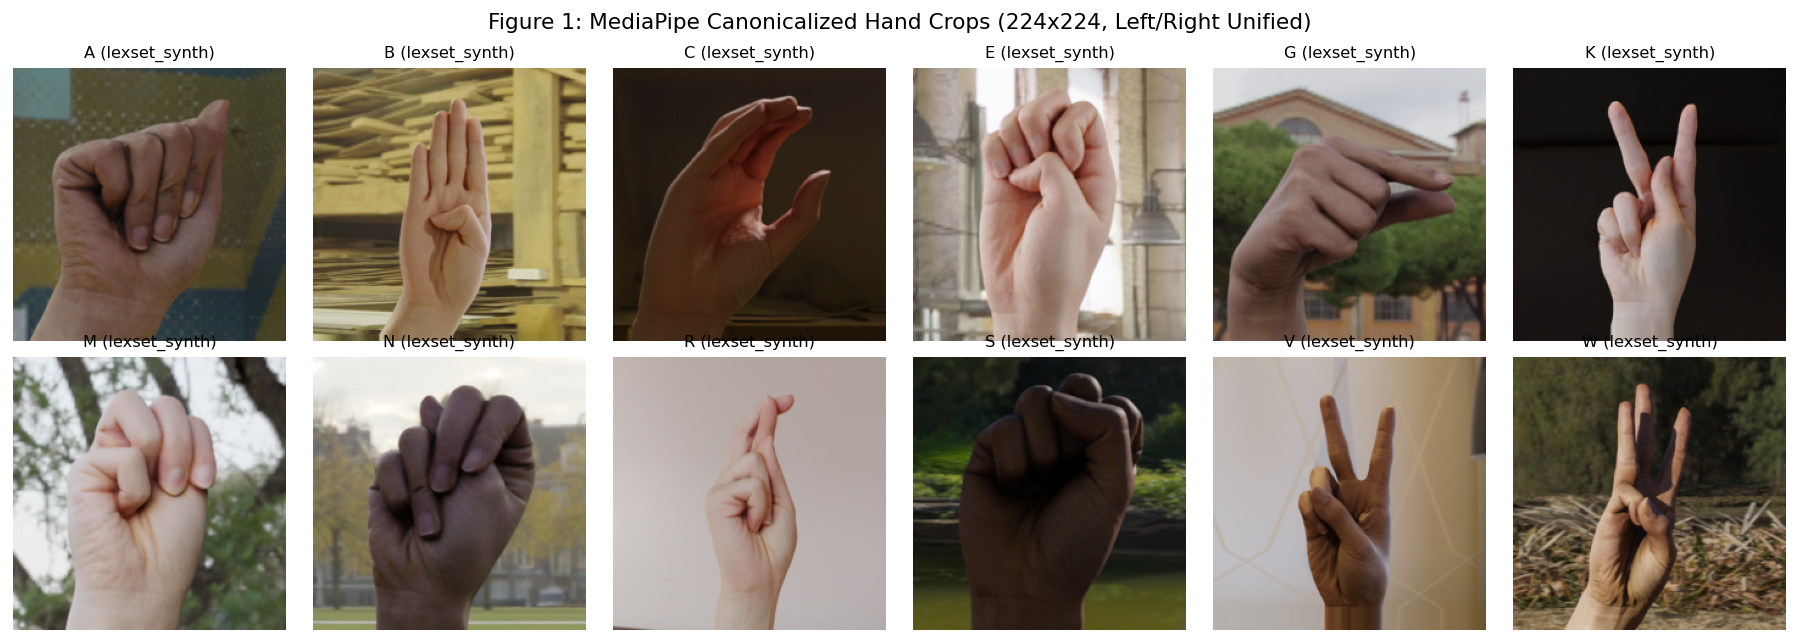

In [4]:
# @title 4. Extract & Cache Hand Crops (224x224) + 98-dim Landmarks + Figure 1 Preview
CACHE_PATH = WORK_DIR / "letter_hybrid_cache_v1.npz"

load_cache = False
if CACHE_PATH.exists():
    with np.load(CACHE_PATH, allow_pickle=True) as cached:
        if "raw_len" in cached.files and int(cached["raw_len"]) == len(raw_df):
            crops_uint8 = cached["crops"]
            geos = cached["geos"]
            labels = cached["labels"]
            sources = cached["sources"]
            load_cache = True
            print(f"Loaded cached {len(labels)} hand crops & landmarks from Drive!")
    if not load_cache:
        CACHE_PATH.unlink()

if not load_cache:
    worker_script = Path("/content/mp_letter_worker.py")
    worker_code = f'''
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

LETTER_CROP_SIZE = {LETTER_CROP_SIZE}
LETTER_GEO_DIM = {LETTER_GEO_DIM}
FINGER_ANGLE_TRIPLES = {FINGER_ANGLE_TRIPLES!r}
FINGERTIP_INDICES = {FINGERTIP_INDICES!r}
FINGER_MCP_REF = {FINGER_MCP_REF!r}
_HAND_DET = None

def init_worker(task_path: str):
    global _HAND_DET
    _HAND_DET = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(
            base_options=mp_python.BaseOptions(model_asset_path=task_path),
            running_mode=vision.RunningMode.IMAGE,
            num_hands=1,
            min_hand_detection_confidence=0.35,
            min_hand_presence_confidence=0.35,
        )
    )

def _angles(pts):
    out = np.zeros(15, dtype=np.float32)
    for i, (a, b, c) in enumerate(FINGER_ANGLE_TRIPLES):
        v1, v2 = pts[a] - pts[b], pts[c] - pts[b]
        out[i] = float(np.clip(np.dot(v1, v2) / (float(np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-6), -1.0, 1.0))
    return out

def _geo98(pts):
    c = pts - pts[0:1]
    scale = max(float(np.linalg.norm(c[9])), 0.02)
    l21 = (c / scale).astype(np.float32)
    a15 = _angles(pts)
    tw = np.array([float(np.linalg.norm(l21[i])) for i in FINGERTIP_INDICES], dtype=np.float32)
    pd_l = [float(np.linalg.norm(l21[FINGERTIP_INDICES[i]] - l21[FINGERTIP_INDICES[j]])) for i in range(5) for j in range(i + 1, 5)]
    tm = np.array([float(np.linalg.norm(l21[a] - l21[b])) for a, b in FINGER_MCP_REF], dtype=np.float32)
    return np.concatenate([l21.reshape(-1), a15, tw, np.array(pd_l, dtype=np.float32), tm], axis=0).astype(np.float32)

def run_img(task):
    idx, path_str = task
    img_bgr = cv2.imread(path_str)
    if img_bgr is None:
        return idx, None
    h0, w0 = img_bgr.shape[:2]
    pad_px = max(16, int(0.18 * max(h0, w0)))
    padded = cv2.copyMakeBorder(img_bgr, pad_px, pad_px, pad_px, pad_px, borderType=cv2.BORDER_REPLICATE)
    rgb = cv2.cvtColor(padded, cv2.COLOR_BGR2RGB)
    res = _HAND_DET.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res or not res.hand_landmarks:
        return idx, None
    pts = np.array([[lm.x, lm.y, lm.z] for lm in res.hand_landmarks[0]], dtype=np.float32)
    handedness = res.handedness[0][0].category_name if (res.handedness and res.handedness[0]) else "Right"
    h, w = padded.shape[:2]
    xs, ys = pts[:, 0] * w, pts[:, 1] * h
    cx, cy = 0.5 * (xs.min() + xs.max()), 0.5 * (ys.min() + ys.max())
    side = max(float(xs.max() - xs.min()), float(ys.max() - ys.min()), 32.0) * 1.45
    half = int(round(side * 0.5))
    x1, y1, x2, y2 = int(round(cx)) - half, int(round(cy)) - half, int(round(cx)) + half, int(round(cy)) + half
    pl, pt, pr, pb = max(0, -x1), max(0, -y1), max(0, x2 - w), max(0, y2 - h)
    crop = padded[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]
    if crop.size == 0:
        return idx, None
    if pl or pt or pr or pb:
        crop = cv2.copyMakeBorder(crop, pt, pb, pl, pr, borderType=cv2.BORDER_REPLICATE)
    canon = pts.copy()
    if handedness == "Left":
        crop = cv2.flip(crop, 1)
        canon[:, 0] = 1.0 - canon[:, 0]
    crop_rgb = cv2.cvtColor(cv2.resize(crop, (LETTER_CROP_SIZE, LETTER_CROP_SIZE), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
    return idx, (crop_rgb.astype(np.uint8), _geo98(canon))
'''
    worker_script.write_text(worker_code, encoding="utf-8")
    import sys
    if "/content" not in sys.path:
        sys.path.insert(0, "/content")
    import mp_letter_worker

    tasks = list(enumerate(raw_df["path"].tolist()))
    results_map = {}
    if EXTRACTION_WORKERS > 1:
        try:
            ctx = multiprocessing.get_context("spawn")
            with ProcessPoolExecutor(
                max_workers=EXTRACTION_WORKERS,
                mp_context=ctx,
                initializer=mp_letter_worker.init_worker,
                initargs=(str(HAND_TASK),),
            ) as pool:
                for idx, out in tqdm(pool.map(mp_letter_worker.run_img, tasks, chunksize=32), total=len(tasks), desc=f"HandLandmarker ({EXTRACTION_WORKERS} workers)"):
                    if out is not None:
                        results_map[idx] = out
        except Exception as exc:
            print("Parallel extraction fallback to single-process:", exc)
            results_map = {}

    if not results_map:
        for idx, p in tqdm(tasks, total=len(tasks), desc="HandLandmarker Extraction"):
            img = cv2.imread(p)
            if img is None:
                continue
            out = extract_crop_and_geo_from_bgr(img)
            if out is not None:
                results_map[idx] = out

    c_list, g_list, y_list, s_list = [], [], [], []
    for idx in sorted(results_map.keys()):
        crop_rgb, geo = results_map[idx]
        row = raw_df.iloc[idx]
        c_list.append(crop_rgb)
        g_list.append(geo)
        y_list.append(int(row["label_id"]))
        s_list.append(str(row["source"]))

    crops_uint8 = np.stack(c_list, axis=0).astype(np.uint8)
    geos = np.stack(g_list, axis=0).astype(np.float32)
    labels = np.array(y_list, dtype=np.int64)
    sources = np.array(s_list)
    np.savez_compressed(CACHE_PATH, raw_len=len(raw_df), crops=crops_uint8, geos=geos, labels=labels, sources=sources)
    print(f"Extracted {len(labels)} / {len(raw_df)} valid hand crops ({100*len(labels)/len(raw_df):.1f}% detection rate).")

ram_gb = (crops_uint8.nbytes + geos.nbytes) / 1e9
print(f"In-RAM cache -> Crops: {crops_uint8.shape} | Geo: {geos.shape} | RAM used: {ram_gb:.2f} GB / {TOTAL_RAM_GB:.1f} GB total")

# Figure 1: Sample Canonical Tight Hand Crops across classes
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
sample_letters = ["A", "B", "C", "E", "G", "K", "M", "N", "R", "S", "V", "W"]
for ax, ch in zip(axes.flat, sample_letters):
    idxs = np.where(labels == LETTER_TO_ID[ch])[0]
    if len(idxs):
        i = int(idxs[0])
        ax.imshow(crops_uint8[i])
        ax.set_title(f"{ch} ({sources[i]})", fontsize=9)
    ax.axis("off")
plt.suptitle("Figure 1: MediaPipe Canonicalized Hand Crops (224x224, Left/Right Unified)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_sample_hand_crops.png", dpi=300)
plt.show()


In [5]:
# @title 5. Stratified Split, Heavy Photometric Augmentations & PyTorch Datasets
from sklearn.model_selection import StratifiedShuffleSplit
import torchvision.transforms.v2 as T

sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.22, random_state=SEED)
train_idx, tmp_idx = next(sss1.split(geos, labels))
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_sub, test_sub = next(sss2.split(geos[tmp_idx], labels[tmp_idx]))
val_idx, test_idx = tmp_idx[val_sub], tmp_idx[test_sub]

# Oversample personal calibration samples in train if provided
cal_tr = [i for i in train_idx if sources[i] == "calibration"]
if cal_tr:
    train_idx = np.concatenate([train_idx] + [np.array(cal_tr)] * 4)

print(f"Splits -> Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

# Store in PyTorch shared RAM (N, 3, 224, 224) uint8 so multi-worker DataLoaders read zero-copy without duplicating memory
crops_chw = torch.from_numpy(crops_uint8).permute(0, 3, 1, 2).contiguous().share_memory_()
geos_shared = torch.from_numpy(geos).share_memory_()
del crops_uint8

train_img_tf = T.Compose([
    T.ToImage(),
    T.RandomApply([T.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.30, hue=0.06)], p=0.85),
    T.RandomAffine(degrees=12, translate=(0.06, 0.06), scale=(0.90, 1.10)),
    T.RandomApply([T.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))], p=0.25),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=IMAGENET_MEAN.tolist(), std=IMAGENET_STD.tolist()),
    T.RandomErasing(p=0.20, scale=(0.02, 0.10)),
])
eval_img_tf = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=IMAGENET_MEAN.tolist(), std=IMAGENET_STD.tolist()),
])

class HybridLetterDataset(Dataset):
    def __init__(self, indices, augment: bool = False):
        self.indices = indices
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        i = int(self.indices[idx])
        img_u8 = crops_chw[i]
        geo_t = geos_shared[i].clone()
        img_t = train_img_tf(img_u8) if self.augment else eval_img_tf(img_u8)
        if self.augment and random.random() < 0.70:
            geo_t[:63] += torch.randn(63, dtype=torch.float32) * 0.012
        return img_t, geo_t, torch.tensor(labels[i], dtype=torch.long)

train_loader = DataLoader(
    HybridLetterDataset(train_idx, augment=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=LOADER_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)
val_loader = DataLoader(
    HybridLetterDataset(val_idx, augment=False),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=min(4, LOADER_WORKERS),
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)
test_loader = DataLoader(
    HybridLetterDataset(test_idx, augment=False),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=min(4, LOADER_WORKERS),
    pin_memory=True,
)


Splits -> Train: 27310 | Val: 3852 | Test: 3852


In [6]:
# @title 6. Define 3 Academic Architectures (RGB-Only, Landmark-Only, HybridHandNet with Gated Fusion)
import torchvision.models as tv_models

class RgbOnlyNet(nn.Module):
    def __init__(self, num_classes: int = 26):
        super().__init__()
        net = tv_models.efficientnet_b0(weights=tv_models.EfficientNet_B0_Weights.DEFAULT)
        self.features = net.features
        self.pool = net.avgpool
        self.head = nn.Sequential(nn.Dropout(0.30), nn.Linear(1280, num_classes))

    def forward(self, image, geo):
        x = self.pool(self.features(image)).flatten(1)
        return self.head(x)

class GeoOnlyNet(nn.Module):
    def __init__(self, geo_dim: int = LETTER_GEO_DIM, num_classes: int = 26):
        super().__init__()
        self.in_proj = nn.Sequential(nn.Linear(geo_dim, 256), nn.LayerNorm(256), nn.SiLU())
        self.block1 = nn.Sequential(nn.Linear(256, 256), nn.LayerNorm(256), nn.SiLU(), nn.Dropout(0.20), nn.Linear(256, 256))
        self.block2 = nn.Sequential(nn.Linear(256, 256), nn.LayerNorm(256), nn.SiLU(), nn.Dropout(0.20), nn.Linear(256, 256))
        self.head = nn.Sequential(nn.LayerNorm(256), nn.Dropout(0.25), nn.Linear(256, num_classes))

    def forward(self, image, geo):
        h = self.in_proj(geo)
        h = h + self.block1(h)
        h = h + self.block2(h)
        return self.head(h)

class HybridHandNet(nn.Module):
    def __init__(self, geo_dim: int = LETTER_GEO_DIM, num_classes: int = 26):
        super().__init__()
        net = tv_models.efficientnet_b0(weights=tv_models.EfficientNet_B0_Weights.DEFAULT)
        self.vis_features = net.features
        self.vis_pool = net.avgpool
        self.vis_proj = nn.Sequential(nn.Linear(1280, 256), nn.LayerNorm(256), nn.SiLU(), nn.Dropout(0.25))

        self.geo_in = nn.Sequential(nn.Linear(geo_dim, 256), nn.LayerNorm(256), nn.SiLU())
        self.geo_res = nn.Sequential(nn.Linear(256, 256), nn.LayerNorm(256), nn.SiLU(), nn.Dropout(0.20), nn.Linear(256, 256))

        # Gated Cross-Modal Attention Fusion
        self.gate_layer = nn.Linear(512, 256)
        self.fusion_mlp = nn.Sequential(
            nn.LayerNorm(256),
            nn.Linear(256, 256),
            nn.SiLU(),
            nn.Dropout(0.25),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, image, geo, return_details: bool = False):
        fmap = self.vis_features(image)
        v = self.vis_proj(self.vis_pool(fmap).flatten(1))
        g = self.geo_in(geo)
        g = g + self.geo_res(g)
        gate = torch.sigmoid(self.gate_layer(torch.cat([v, g], dim=1)))
        fused = gate * v + (1.0 - gate) * g
        emb = self.fusion_mlp(fused)
        logits = self.classifier(emb)
        if return_details:
            return logits, gate, emb, fmap
        return logits

print("HybridHandNet params:", round(sum(p.numel() for p in HybridHandNet().parameters()) / 1e6, 2), "M")


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 136MB/s]


HybridHandNet params: 4.7 M


In [7]:
# @title 7. Training Engine & 3-Way Academic Benchmark
from copy import deepcopy
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

def evaluate_letter_model(model, loader):
    model.eval()
    all_logits, all_y = [], []
    t0 = time.perf_counter()
    with torch.no_grad():
        for img_b, geo_b, yb in loader:
            logits = model(img_b.to(DEVICE, non_blocking=True), geo_b.to(DEVICE, non_blocking=True))
            all_logits.append(logits.cpu().numpy())
            all_y.append(yb.numpy())
    elapsed_ms = ((time.perf_counter() - t0) / max(len(loader.dataset), 1)) * 1000.0
    logits_np = np.concatenate(all_logits, axis=0)
    y_true = np.concatenate(all_y, axis=0)
    probs = torch.softmax(torch.from_numpy(logits_np), dim=-1).numpy()
    preds = np.argmax(probs, axis=1)
    return {
        "top1": accuracy_score(y_true, preds),
        "top3": top_k_accuracy_score(y_true, probs, k=3, labels=list(range(len(LETTERS_26)))),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, preds, average="weighted", zero_division=0),
        "latency_ms": elapsed_ms,
        "y_true": y_true,
        "y_pred": preds,
        "probs": probs,
    }

def train_letter_model(model, epochs: int, lr: float, name: str):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr * 0.02)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.08)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_f1 = -1.0
    best_state = deepcopy(model.state_dict())
    history = {"train_loss": [], "val_acc": [], "val_f1": []}

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for img_b, geo_b, yb in train_loader:
            img_b, geo_b, yb = img_b.to(DEVICE, non_blocking=True), geo_b.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                logits = model(img_b, geo_b)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(optimizer)
            scaler.update()
            total_loss += float(loss.item()) * img_b.size(0)

        scheduler.step()
        val_m = evaluate_letter_model(model, val_loader)
        tr_loss = total_loss / max(len(train_loader.dataset), 1)
        history["train_loss"].append(tr_loss)
        history["val_acc"].append(val_m["top1"])
        history["val_f1"].append(val_m["macro_f1"])

        if val_m["macro_f1"] > best_f1:
            best_f1 = val_m["macro_f1"]
            best_state = deepcopy(model.state_dict())

        if ep in (1, epochs) or ep % max(1, epochs // 4) == 0:
            print(f"[{name}] Ep {ep:02d}/{epochs} | Loss {tr_loss:.4f} | Val Acc {val_m['top1']*100:.2f}% | Val F1 {val_m['macro_f1']*100:.2f}%")

    model.load_state_dict(best_state)
    torch.save(best_state, WORK_DIR / f"{name}_best.pt")
    return model, history

print("=== Training Baseline 1: RGB-Only EfficientNet-B0 ===")
rgb_net, hist_rgb = train_letter_model(RgbOnlyNet(26), epochs=14, lr=4e-4, name="rgb_only")

print("\n=== Training Baseline 2: Landmark-Only ResMLP (98-dim) ===")
geo_net, hist_geo = train_letter_model(GeoOnlyNet(LETTER_GEO_DIM, 26), epochs=24, lr=1e-3, name="geo_only")

print("\n=== Training Proposed Model: HybridHandNet (EfficientNet-B0 + 98d Geo + Gated Fusion) ===")
hybrid_net, hist_hyb = train_letter_model(HybridHandNet(LETTER_GEO_DIM, 26), epochs=18, lr=4e-4, name="hybrid_handnet")

res_rgb = evaluate_letter_model(rgb_net, test_loader)
res_geo = evaluate_letter_model(geo_net, test_loader)
res_hyb = evaluate_letter_model(hybrid_net, test_loader)

bench_df = pd.DataFrame([
    {"Model": "Baseline 1: RGB-Only EfficientNet-B0", "Top-1 Acc (%)": res_rgb["top1"]*100, "Top-3 Acc (%)": res_rgb["top3"]*100, "Macro F1 (%)": res_rgb["macro_f1"]*100, "Params (M)": sum(p.numel() for p in rgb_net.parameters())/1e6},
    {"Model": "Baseline 2: Landmark-Only ResMLP (98d)", "Top-1 Acc (%)": res_geo["top1"]*100, "Top-3 Acc (%)": res_geo["top3"]*100, "Macro F1 (%)": res_geo["macro_f1"]*100, "Params (M)": sum(p.numel() for p in geo_net.parameters())/1e6},
    {"Model": "Proposed: HybridHandNet (Gated Fusion)", "Top-1 Acc (%)": res_hyb["top1"]*100, "Top-3 Acc (%)": res_hyb["top3"]*100, "Macro F1 (%)": res_hyb["macro_f1"]*100, "Params (M)": sum(p.numel() for p in hybrid_net.parameters())/1e6},
])
bench_df.to_csv(WORK_DIR / "letter_benchmark_results.csv", index=False)
display(bench_df.round(2))


=== Training Baseline 1: RGB-Only EfficientNet-B0 ===
[rgb_only] Ep 01/14 | Loss 0.8905 | Val Acc 99.87% | Val F1 99.87%
[rgb_only] Ep 03/14 | Loss 0.5455 | Val Acc 99.97% | Val F1 99.97%
[rgb_only] Ep 06/14 | Loss 0.5317 | Val Acc 99.97% | Val F1 99.97%
[rgb_only] Ep 09/14 | Loss 0.5284 | Val Acc 99.97% | Val F1 99.97%
[rgb_only] Ep 12/14 | Loss 0.5255 | Val Acc 99.97% | Val F1 99.97%
[rgb_only] Ep 14/14 | Loss 0.5247 | Val Acc 99.97% | Val F1 99.97%

=== Training Baseline 2: Landmark-Only ResMLP (98-dim) ===
[geo_only] Ep 01/24 | Loss 0.8832 | Val Acc 96.39% | Val F1 96.35%
[geo_only] Ep 06/24 | Loss 0.6052 | Val Acc 98.21% | Val F1 98.19%
[geo_only] Ep 12/24 | Loss 0.5715 | Val Acc 97.82% | Val F1 97.79%
[geo_only] Ep 18/24 | Loss 0.5506 | Val Acc 98.70% | Val F1 98.67%
[geo_only] Ep 24/24 | Loss 0.5410 | Val Acc 98.88% | Val F1 98.87%

=== Training Proposed Model: HybridHandNet (EfficientNet-B0 + 98d Geo + Gated Fusion) ===
[hybrid_handnet] Ep 01/18 | Loss 0.8853 | Val Acc 99.74% |

,Model,Top-1 Acc (%),Top-3 Acc (%),Macro F1 (%),Params (M)
0,Baseline 1: RGB-Only EfficientNet-B0,99.84,99.95,99.84,4.04
1,Baseline 2: Landmark-Only ResMLP (98d),98.70,99.61,98.69,0.30
2,Proposed: HybridHandNet (Gated Fusion),99.90,100.00,99.89,4.70


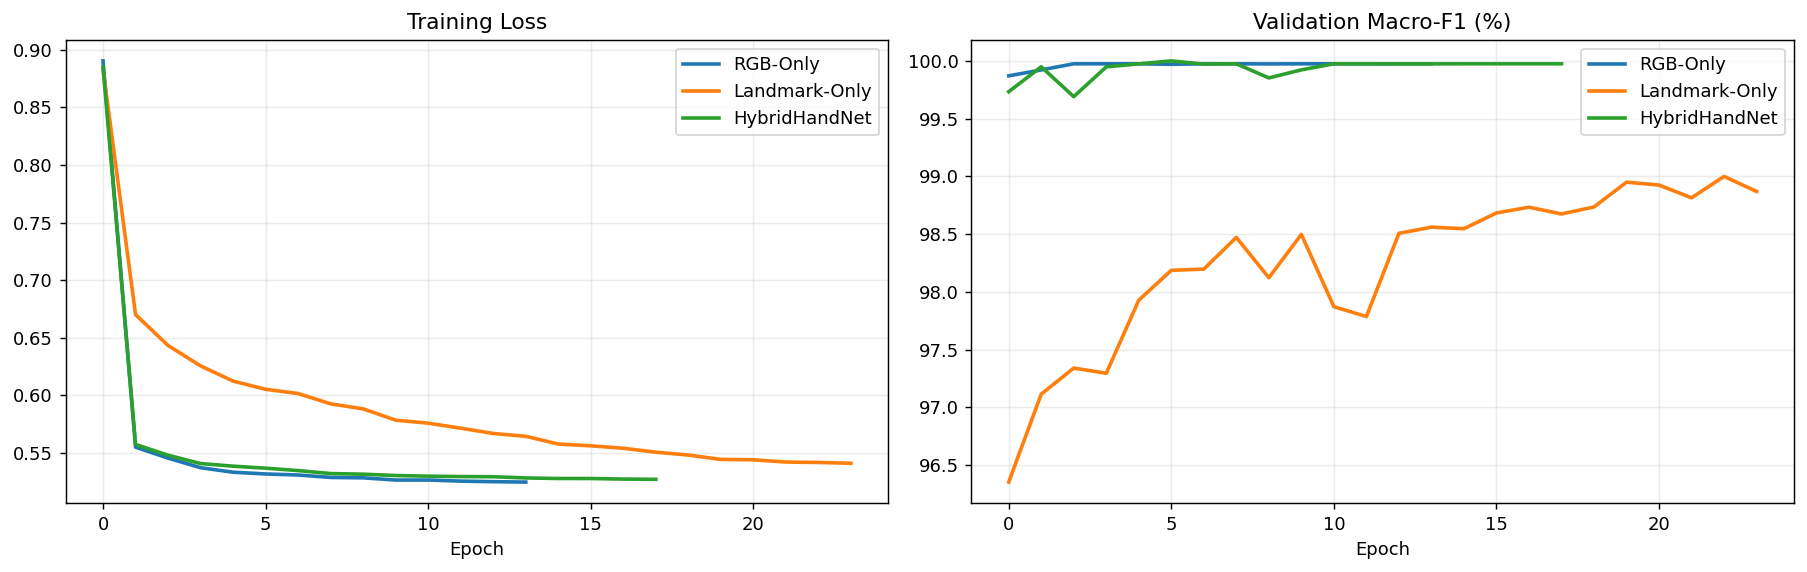

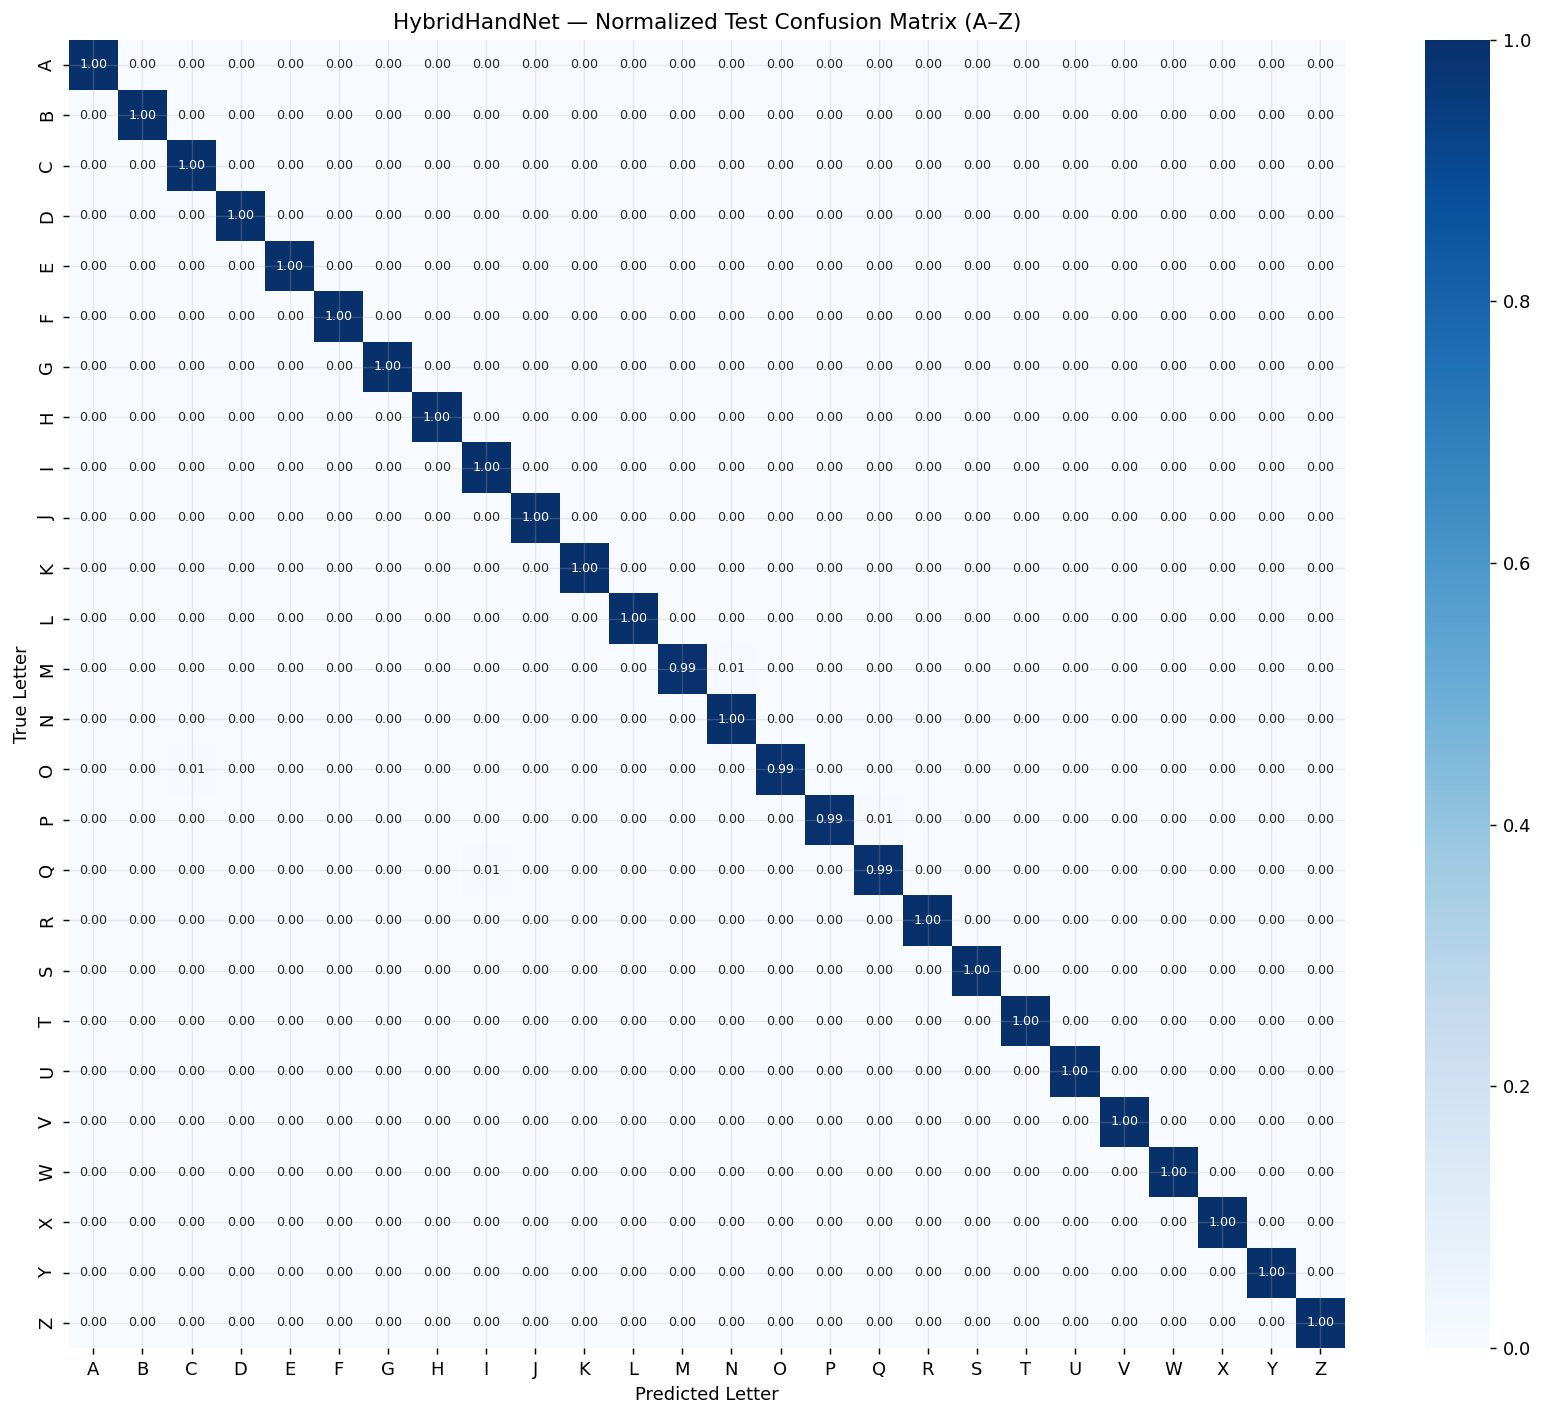

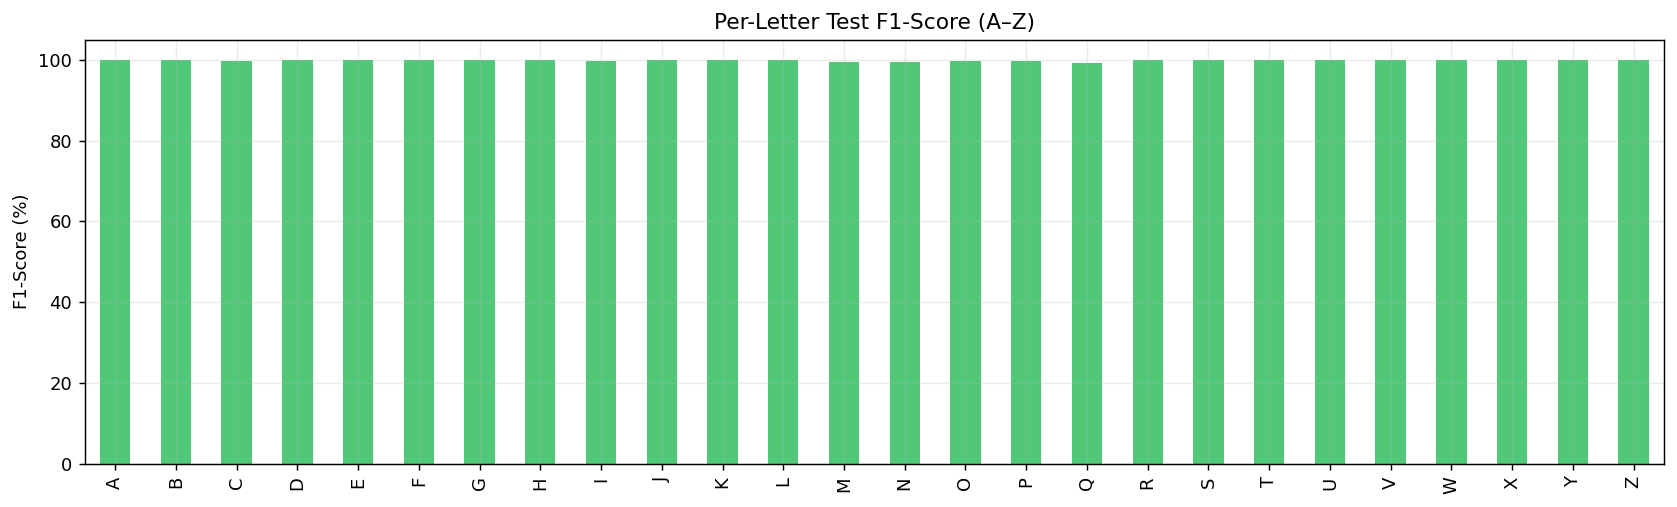

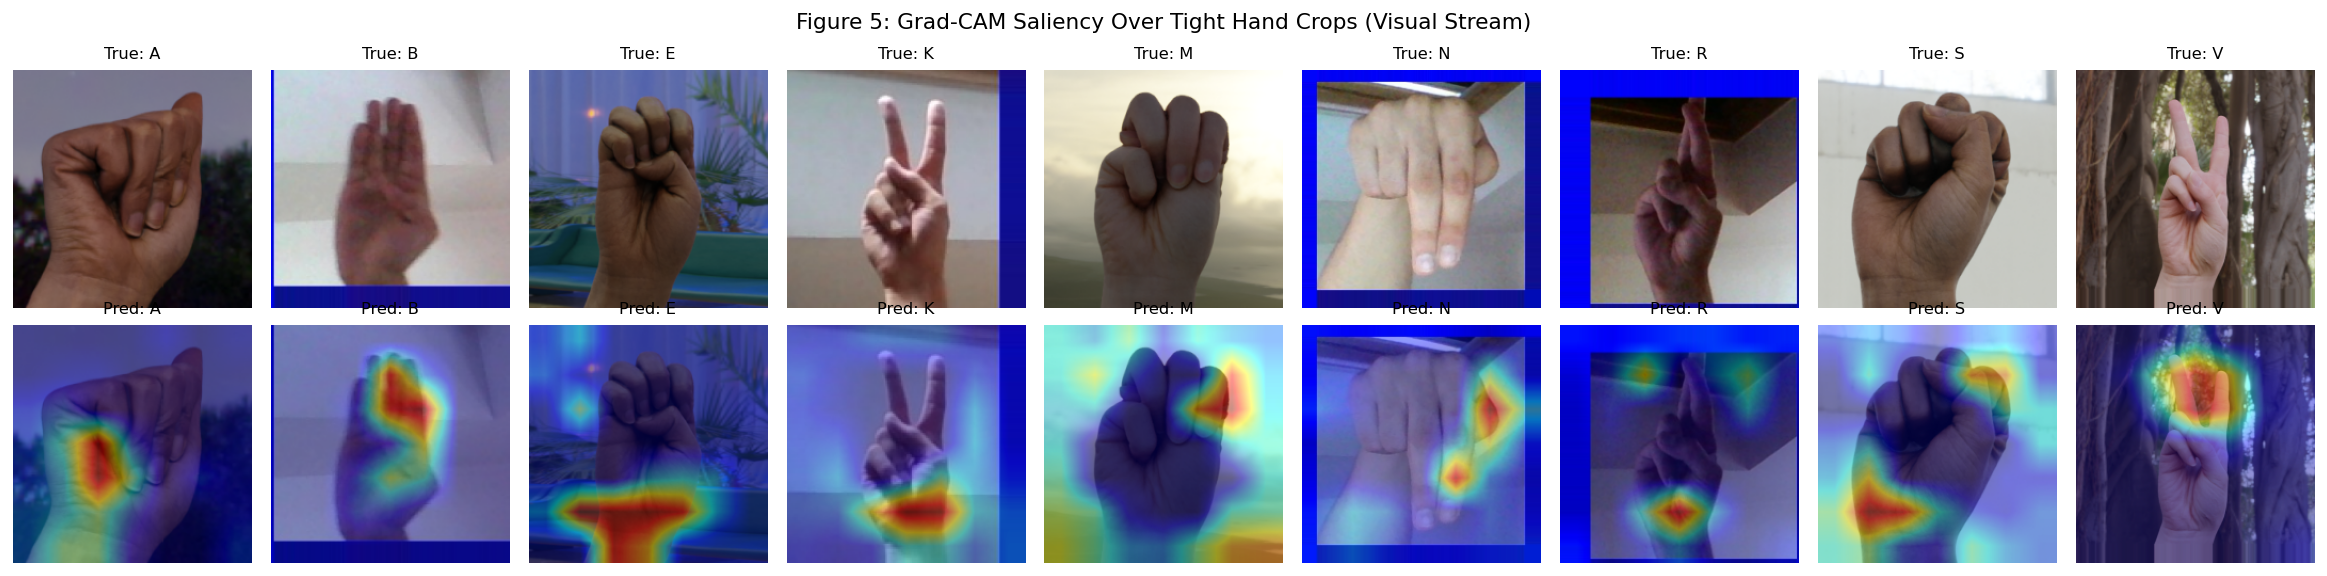

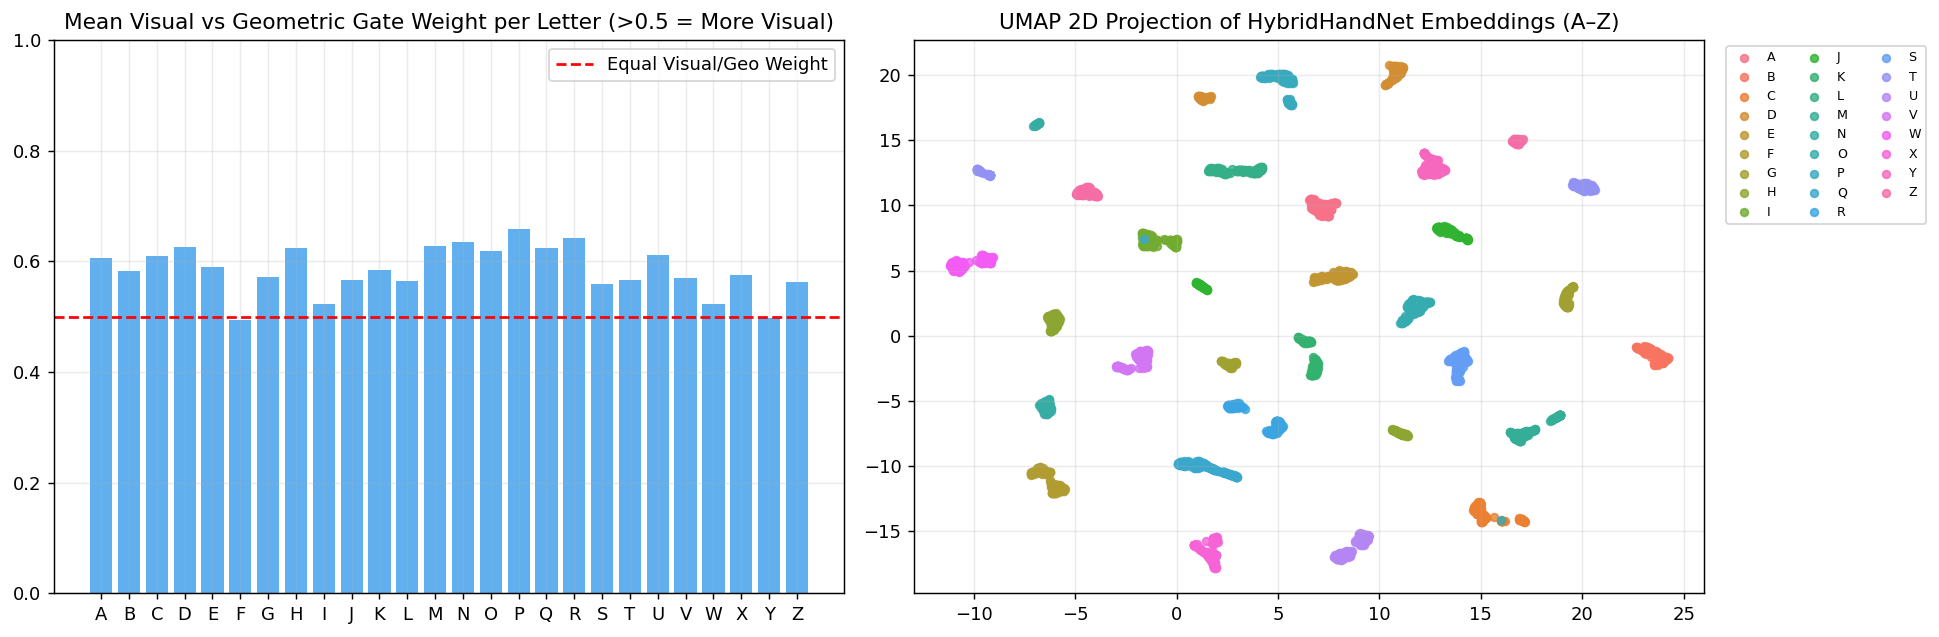

In [8]:
# @title 8. Academic Visualizations (Training Curves, 26x26 Confusion Matrix, F1, Grad-CAM, Gate & UMAP)
from sklearn.metrics import confusion_matrix, classification_report
import umap

# Fig 2: Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, hist in [("RGB-Only", hist_rgb), ("Landmark-Only", hist_geo), ("HybridHandNet", hist_hyb)]:
    axes[0].plot(hist["train_loss"], label=lbl, linewidth=2)
    axes[1].plot([v * 100 for v in hist["val_f1"]], label=lbl, linewidth=2)
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].set_title("Validation Macro-F1 (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_letter_training_curves.png", dpi=300)
plt.show()

# Fig 3: 26x26 Confusion Matrix
cm = confusion_matrix(res_hyb["y_true"], res_hyb["y_pred"], labels=list(range(26)), normalize="true")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LETTERS_26, yticklabels=LETTERS_26, ax=ax, annot_kws={"size": 7})
ax.set_title("HybridHandNet — Normalized Test Confusion Matrix (A–Z)")
ax.set_xlabel("Predicted Letter")
ax.set_ylabel("True Letter")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_letter_confusion_matrix.png", dpi=300)
plt.show()

# Fig 4: Per-Letter F1 Bar Chart
rep = classification_report(res_hyb["y_true"], res_hyb["y_pred"], labels=list(range(26)), target_names=LETTERS_26, output_dict=True, zero_division=0)
f1_s = pd.Series({ch: rep[ch]["f1-score"] * 100 for ch in LETTERS_26})
fig, ax = plt.subplots(figsize=(13, 4))
f1_s.plot(kind="bar", ax=ax, color=["#e06c75" if v < 90 else "#50c878" for v in f1_s.values])
ax.set_ylim(0, 105)
ax.set_ylabel("F1-Score (%)")
ax.set_title("Per-Letter Test F1-Score (A–Z)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_per_letter_f1.png", dpi=300)
plt.show()

# Fig 5: Grad-CAM Visual Explanations on EfficientNet-B0 Spatial Features
hybrid_net.eval()
focus_letters = ["A", "B", "E", "K", "M", "N", "R", "S", "V"]
fig, axes = plt.subplots(2, len(focus_letters), figsize=(18, 4.5))

for col_idx, ch in enumerate(focus_letters):
    cls_id = LETTER_TO_ID[ch]
    matches = [i for i in test_idx if labels[i] == cls_id]
    if not matches:
        continue
    ds_idx = int(matches[0])
    img_raw = crops_chw[ds_idx].permute(1, 2, 0).numpy()
    img_t = eval_img_tf(crops_chw[ds_idx]).unsqueeze(0).to(DEVICE)
    geo_t = geos_shared[ds_idx].unsqueeze(0).to(DEVICE)

    hybrid_net.zero_grad()
    fmap = hybrid_net.vis_features(img_t)
    fmap.retain_grad()
    v = hybrid_net.vis_proj(hybrid_net.vis_pool(fmap).flatten(1))
    g = hybrid_net.geo_in(geo_t)
    g = g + hybrid_net.geo_res(g)
    gate = torch.sigmoid(hybrid_net.gate_layer(torch.cat([v, g], dim=1)))
    emb = hybrid_net.fusion_mlp(gate * v + (1.0 - gate) * g)
    logits = hybrid_net.classifier(emb)
    pred_id = int(logits.argmax(dim=1).item())
    logits[0, pred_id].backward()

    fmap_t = fmap[0].detach()
    grads = fmap.grad[0].detach()
    weights = grads.mean(dim=(1, 2), keepdim=True)
    cam = torch.relu((weights * fmap_t).sum(dim=0)).cpu().numpy()
    cam = cv2.resize(cam, (LETTER_CROP_SIZE, LETTER_CROP_SIZE))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-6)
    heatmap = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    overlay = np.uint8(0.58 * img_raw + 0.42 * heatmap)

    axes[0, col_idx].imshow(img_raw)
    axes[0, col_idx].set_title(f"True: {ch}", fontsize=9)
    axes[0, col_idx].axis("off")
    axes[1, col_idx].imshow(overlay)
    axes[1, col_idx].set_title(f"Pred: {LETTERS_26[pred_id]}", fontsize=9)
    axes[1, col_idx].axis("off")

plt.suptitle("Figure 5: Grad-CAM Saliency Over Tight Hand Crops (Visual Stream)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_gradcam_letters.png", dpi=300)
plt.show()

# Fig 6: Modality Gate Analysis + UMAP Embeddings
gates, embs = [], []
with torch.no_grad():
    for img_b, geo_b, _ in test_loader:
        _, g_w, e, _ = hybrid_net(img_b.to(DEVICE), geo_b.to(DEVICE), return_details=True)
        gates.append(g_w.mean(dim=1).cpu().numpy())
        embs.append(e.cpu().numpy())
gates_np = np.concatenate(gates, axis=0)
embs_np = np.concatenate(embs, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
gate_by_cls = [gates_np[res_hyb["y_true"] == c].mean() for c in range(26)]
axes[0].bar(LETTERS_26, gate_by_cls, color="#61afef")
axes[0].axhline(0.5, color="red", linestyle="--", label="Equal Visual/Geo Weight")
axes[0].set_ylim(0, 1)
axes[0].set_title("Mean Visual vs Geometric Gate Weight per Letter (>0.5 = More Visual)")
axes[0].legend()

proj = umap.UMAP(n_neighbors=15, min_dist=0.2, random_state=SEED).fit_transform(embs_np)
pal = sns.color_palette("husl", 26)
for c, ch in enumerate(LETTERS_26):
    m = (res_hyb["y_true"] == c)
    if m.any():
        axes[1].scatter(proj[m, 0], proj[m, 1], color=pal[c], label=ch, s=18, alpha=0.8)
axes[1].set_title("UMAP 2D Projection of HybridHandNet Embeddings (A–Z)")
axes[1].legend(ncol=3, fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_gate_and_umap.png", dpi=300)
plt.show()


In [9]:
# @title 9. Export Verified ONNX Model + Config + Download Zip for Windows App
import onnx
import onnxruntime as ort

class HybridHandExport(nn.Module):
    def __init__(self, core: HybridHandNet):
        super().__init__()
        self.core = core

    def forward(self, image, geo):
        return self.core(image, geo, return_details=False)

export_net = HybridHandExport(hybrid_net).cpu().eval()
dummy_img = torch.randn(1, 3, LETTER_CROP_SIZE, LETTER_CROP_SIZE, dtype=torch.float32)
dummy_geo = torch.randn(1, LETTER_GEO_DIM, dtype=torch.float32)

onnx_path = EXPORT_DIR / "asl_letters_hybrid.onnx"
try:
    torch.onnx.export(
        export_net,
        (dummy_img, dummy_geo),
        str(onnx_path),
        input_names=["image", "geo"],
        output_names=["logits"],
        dynamic_axes={"image": {0: "batch"}, "geo": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
        dynamo=False,
    )
except TypeError:
    torch.onnx.export(
        export_net,
        (dummy_img, dummy_geo),
        str(onnx_path),
        input_names=["image", "geo"],
        output_names=["logits"],
        dynamic_axes={"image": {0: "batch"}, "geo": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
    )

onnx.checker.check_model(onnx.load(str(onnx_path)))
ort_sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
with torch.no_grad():
    pt_out = export_net(dummy_img, dummy_geo).numpy()
ort_out = ort_sess.run(["logits"], {"image": dummy_img.numpy(), "geo": dummy_geo.numpy()})[0]
max_diff = float(np.max(np.abs(pt_out - ort_out)))
print(f"ONNX Parity Check -> max_abs_diff = {max_diff:.2e} (threshold < 1e-4)")
assert max_diff < 1e-4

config_payload = {
    "feature_version": "letter_v1_hybrid_224_98",
    "labels": LETTERS_26,
    "crop_size": LETTER_CROP_SIZE,
    "geo_dim": LETTER_GEO_DIM,
    "test_top1_acc": round(float(res_hyb["top1"]), 4),
    "test_macro_f1": round(float(res_hyb["macro_f1"]), 4),
}
(EXPORT_DIR / "letter_model_config.json").write_text(json.dumps(config_payload, indent=2), encoding="utf-8")

bundle_zip = shutil.make_archive(str(WORK_DIR / "asl_letters_export"), "zip", str(EXPORT_DIR))
print("Created export bundle:", bundle_zip)
print("Copy asl_letters_hybrid.onnx and letter_model_config.json into your local Windows 'models/' folder!")

try:
    from google.colab import files
    files.download(bundle_zip)
except Exception:
    print("Manual download ready at:", bundle_zip)


ONNX Parity Check -> max_abs_diff = 1.78e-05 (threshold < 1e-4)
Created export bundle: /content/drive/MyDrive/ASL_Project/letters_hybrid/asl_letters_export.zip
Copy asl_letters_hybrid.onnx and letter_model_config.json into your local Windows 'models/' folder!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>